<a href="https://colab.research.google.com/github/tikotama/Jeffrey_INFO4670_Fall2026/blob/main/assignment_1a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1 — Making Sense of Northgate through Visualization
**INFO 4670 · Data Analysis and Knowledge Discovery**  ·  **Due: Sunday, 11:59 PM**

**Name:** \_\_\_\_\_\_\_\_    **Date:** \_\_\_\_\_\_\_\_

**The situation.** The Provost's question stands: *which students are struggling, and can we see it earlier?* This week you answer it the way analysts do — not by reading rows, but by drawing the data. Every chart below is built by **adapting code from the Guided notebook**; the intellectual work is choosing the right chart and reading it honestly.

**For every chart you make, you must:**
1. **Choose** the chart type that fits the variable(s) and the question.
2. **Build** it in Colab from the Northgate files.
3. **Label** it fully — title, axis labels, and units/legend. *An unlabeled chart is an unfinished chart.*
4. **Write a STAR story** underneath it — Scope · Track · Articulate · Respond (defined on the Concepts deck).

**How to work:** run Setup and Load first. Then, for each question, copy the closest cell from the Guided notebook into the empty cell, adapt it, and fill in the STAR cell below it.

**Submit:** push this notebook to GitHub and submit the **GitHub link** in Canvas. (See the setup doc: *Colab_GitHub_Setup_INFO4670_Fall2026*.)

## Setup — run this first (you don't need to change it)

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Northgate house style (optional, but keeps your charts consistent)
NAVY = "#22303A"
RUST = "#C0562F"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"]   = (8, 5)
plt.rcParams["axes.titlesize"]   = 13
plt.rcParams["axes.titleweight"] = "bold"

## Load the data — run this, then look before you plot

In [32]:
# STEP 1 — get the data into this notebook. Pick ONE option, then run.

DATA_DIR = "."   # OPTION 2 (default) · drag the 3 CSVs into the file panel on the left

# OPTION 1 · read from Google Drive — uncomment and edit the path:
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_DIR = "/content/drive/MyDrive/.../Data"

import os
students = pd.read_csv(os.path.join(DATA_DIR, "student_records.csv"))
weekly   = pd.read_csv(os.path.join(DATA_DIR, "weekly_activity.csv"))
students.head()

,student_id,major,age,housing,commute_miles,work_hours_per_week,advisor_meetings,credits_attempted,final_gpa,study_hours_reported,enrollment_date,dropped_out
0,NU-101508,Data Science,27,Off-Campus,7.6,15,1,81,1.86,NaN,2023-09-13,1
1,NU-102438,Learning Technologies,25,With Family,14.3,35,1,100,2.06,9.5,2023-10-19,0
2,NU-102385,Learning Technologies,26,With Family,3.4,18,9,77,3.41,19.1,11/16/2022,0
3,NU-100767,Cyber Security,22,On-Campus,23.7,40,1,65,1.73,8.1,2024-05-03,0
4,NU-106054,Information Technology,21,Off-Campus,2.3,20,4,59,2.37,6.6,10/24/2022,0


In [33]:
# how many rows, which columns, what types?
students.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2027 entries, 0 to 2026
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            2027 non-null   object 
 1   major                 2027 non-null   object 
 2   age                   2027 non-null   int64  
 3   housing               2027 non-null   object 
 4   commute_miles         2027 non-null   float64
 5   work_hours_per_week   2027 non-null   int64  
 6   advisor_meetings      2027 non-null   int64  
 7   credits_attempted     2027 non-null   int64  
 8   final_gpa             2027 non-null   float64
 9   study_hours_reported  1772 non-null   float64
 10  enrollment_date       2027 non-null   object 
 11  dropped_out           2027 non-null   int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 190.2+ KB


# Part A — Guided questions
Build **one chart per question**. Each maps to one chart family from this week. Copy the closest Guided-notebook cell, adapt it, label it, then write its STAR story.

### Q1 · One quantitative variable
**How many hours per week do Northgate students work?** Describe what's typical, how spread out it is, and whether anyone stands apart.
→ *histogram* (add a *box plot* if it helps). Column: `work_hours_per_week` (from `students`).

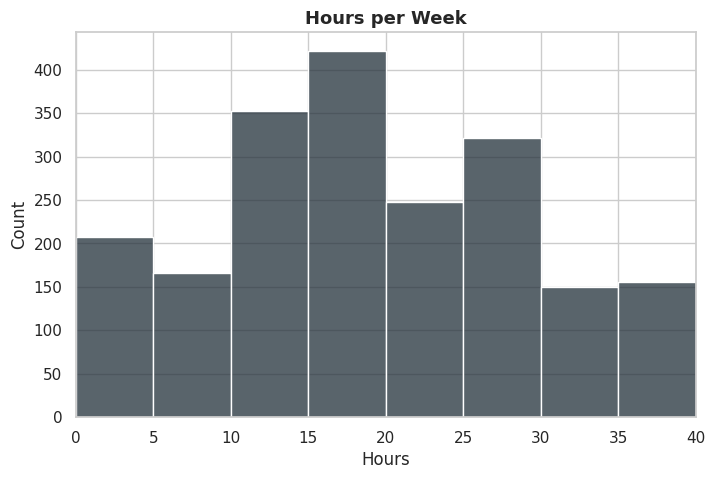

In [34]:
# Copy the closest cell from the Guided notebook, then fill in the blanks.
#
#   fig, ax = plt.subplots()
#   sns.__________(data=________, x="__________", color=NAVY, ax=ax)   # which chart? which column(s)?
#   ax.set_title("__________")
#   ax.set_xlabel("__________")
#   ax.set_ylabel("__________")
#   plt.show()

# --- your code below ---

fig, ax = plt.subplots()
sns.histplot(data=students, x="work_hours_per_week", color=NAVY, ax=ax, bins = [0, 5, 10, 15, 20, 25, 30, 35, 40])
ax.set_title("Hours per Week")
ax.set_xlabel("Hours")
ax.set_ylabel("Count")
ax.set_xlim(left = 0, right = 40)
plt.show()


**STAR story — Q1**

- **Scope —** The chart indicates that students are frequently engaged in substantial work hours during the week with a range of 0 hours up to full-time employment. It pulls data from *Students* and the data which is binned into the histograph is the *work_hours_per_week*.

- **Track —** This chart answers the question about the experiences students have related to their employment in addition to coursework.

- **Articulate —** The chart indicates there is a wide range of employment levels with a concentration between 10 and 30 hours. There likely is a significant experiential difference in available studytime between those students work no hours and those that are working at or near full-time.

- **Respond —** I do not find any oddities in this chart as the data is somewhat to be expected in the spread and concentrations. I am curious if the amount of employment hours impacts positively or negatively the academic outcomes including GPA and retention rates.

### Q2 · One categorical variable
**How does enrollment compare across majors?**
→ *sorted bar chart*. Column: `major` (from `students`).

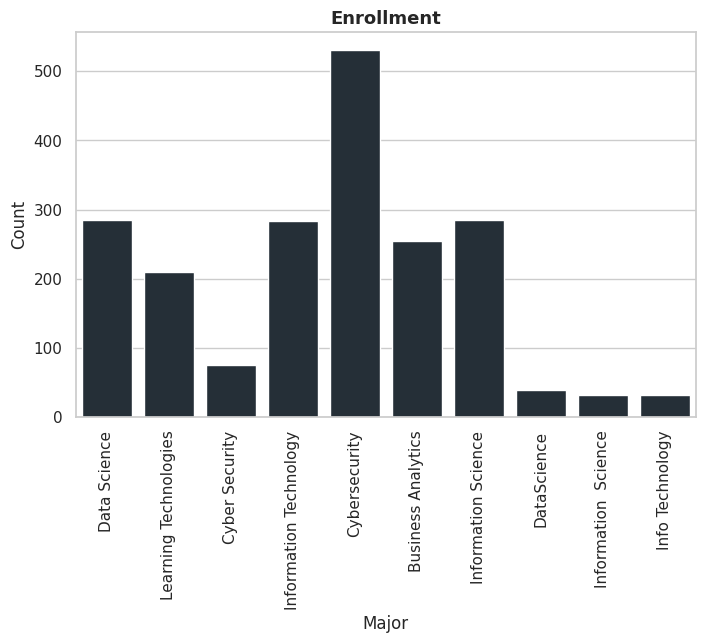

In [35]:
# Copy the closest cell from the Guided notebook, then fill in the blanks.
#
#   fig, ax = plt.subplots()
#   sns.__________(data=________, x="__________", color=NAVY, ax=ax)   # which chart? which column(s)?
#   ax.set_title("__________")
#   ax.set_xlabel("__________")
#   ax.set_ylabel("__________")
#   plt.show()

# --- your code below ---

fig, ax = plt.subplots()
sns.countplot(data=students, x="major", color=NAVY, ax=ax)
ax.set_title("Enrollment")
ax.set_xlabel("Major")
ax.set_ylabel("Count")
ax.tick_params(axis='x', rotation=90)
plt.show()


**STAR story — Q2**

- **Scope —** This chart shows the data pulled from *Students* and reports the count of students in the various different majors utilizing the field *major*.

- **Track —** This chart indicates which majors have many or few students.

- **Articulate —** Applying statistical analysis to this type of chart does not make sense, but it does indicate the largest major by students is Cybersecurity. Five majors have moderate enrollment and then four majors have relatively small enrollment numbers.

- **Respond —** I would want to have more information related to the low enrollment majors to look at their trends across semesters or academic years, if they are new programs, or if the enrollment justifies the number of faculty servicing those majors.

### Q3 · A quantity, split by category
**Does final GPA differ across majors?** Read the exceptions, not just the boxes.
→ *box plot per major*. Columns: `final_gpa` and `major` (from `students`).

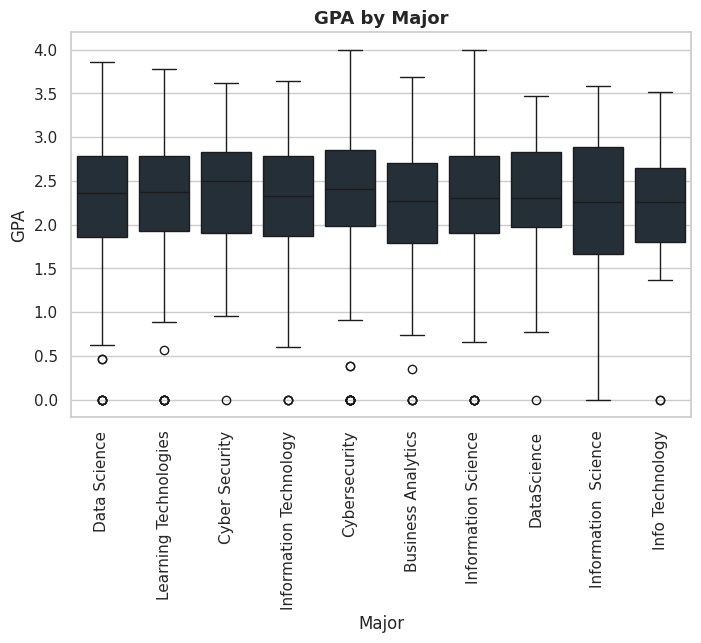

In [36]:
# Copy the closest cell from the Guided notebook, then fill in the blanks.
#
#   fig, ax = plt.subplots()
#   sns.__________(data=________, x="__________", color=NAVY, ax=ax)   # which chart? which column(s)?
#   ax.set_title("__________")
#   ax.set_xlabel("__________")
#   ax.set_ylabel("__________")
#   plt.show()

# --- your code below ---

fig, ax = plt.subplots()
sns.boxplot(data=students, x="major", y="final_gpa", color=NAVY, ax=ax)
ax.set_title("GPA by Major")
ax.set_xlabel("Major")
ax.set_ylabel("GPA")
ax.tick_params(axis='x', rotation=90)
plt.show()


**STAR story — Q3**

- **Scope —** This chart indicates the range, first quartile, third quartile, and outliers of GPAs in the various different majors utilizing the data in *Students* reported in the fields *major* and *final_gpa*.

- **Track —** This chart gives us a good way to view the basic statistical information available from the *final_gpa* when grouped by the *major* field.

- **Articulate —** All majors have roughly comparable rigor as measured through GPA outcomes.

- **Respond —** I am quite sure the outliers at the 0.0 GPA mark are all new students that do not have an established GPA, but I would want to confirm that assumption. If that is the case, omitting those students that have not established a GPA would make the chart potentially more valid.

### Q4 · Two quantitative variables
**Is there a relationship between how far students commute and their final GPA?** Remember: *association is not causation.*
→ *scatterplot with a trend line*. Columns: `commute_miles` and `final_gpa` (from `students`).

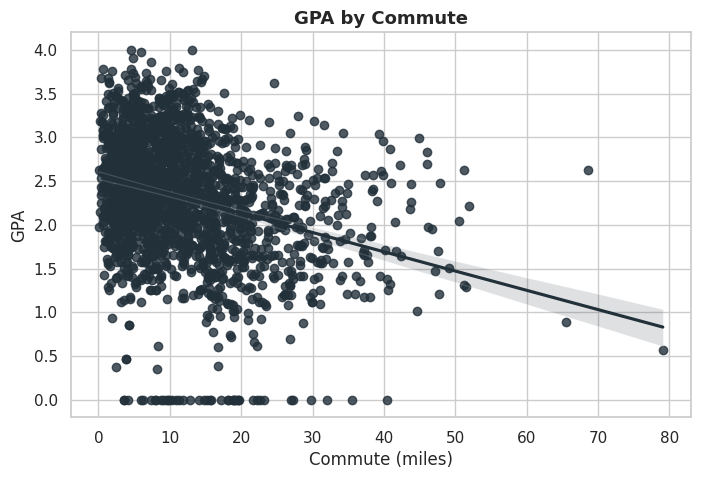

In [37]:
# Copy the closest cell from the Guided notebook, then fill in the blanks.
#
#   fig, ax = plt.subplots()
#   sns.__________(data=________, x="__________", color=NAVY, ax=ax)   # which chart? which column(s)?
#   ax.set_title("__________")
#   ax.set_xlabel("__________")
#   ax.set_ylabel("__________")
#   plt.show()

# --- your code below ---

fig, ax = plt.subplots()
sns.regplot(data=students, x="commute_miles", y="final_gpa", color=NAVY, ax=ax)
ax.set_title("GPA by Commute")
ax.set_xlabel("Commute (miles)")
ax.set_ylabel("GPA")
plt.show()


**STAR story — Q4**

- **Scope —** The chart is a scatter plot of the students GPAs mapped against the students' commute distance in miles. The data comes from *Students* and the fields are *commute_miles* and *final_gpa*.

- **Track —** This chart is intended to check for a correlation between the distance a student travels and the potential impact on their GPA.

- **Articulate —** The chart indicates there is a negative correlation with increased miles of commute and and GPA. It is also possible to recognize most students live within a relatively short distance due the clustering on the left side of the graph.

- **Respond —** Again the presence of 0.0 GPAs seems to be an issue with unestablished GPAs and I would want to address that shortcoming of the data. I would also like to filter this dataset by something indicating the progress through the program (class or hours).

### Q5 · Over time
**How does student engagement change across the semester?**
→ *line chart* of average weekly activity. Use the `weekly` table: `week` and `minutes_active` (you'll need to average by week first — see the Guided notebook).

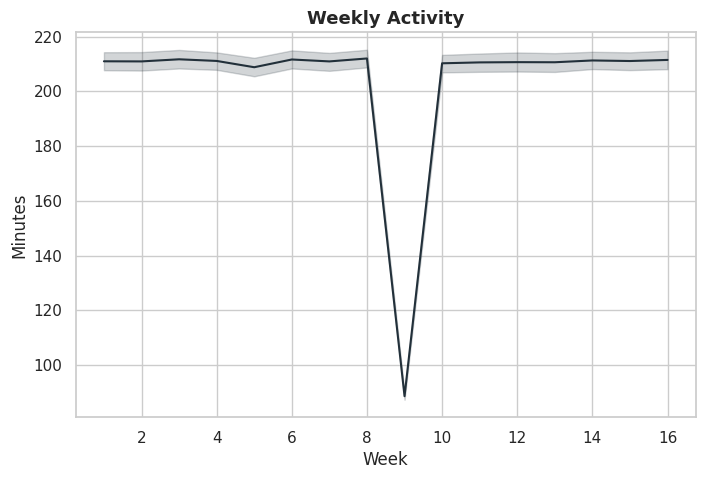

In [38]:
# Copy the closest cell from the Guided notebook, then fill in the blanks.
#
#   fig, ax = plt.subplots()
#   sns.__________(data=________, x="__________", color=NAVY, ax=ax)   # which chart? which column(s)?
#   ax.set_title("__________")
#   ax.set_xlabel("__________")
#   ax.set_ylabel("__________")
#   plt.show()

# --- your code below ---

fig, ax = plt.subplots()
sns.lineplot(data=weekly, x="week", y="minutes_active", color=NAVY, ax=ax)
ax.set_title("Weekly Activity")
ax.set_xlabel("Week")
ax.set_ylabel("Minutes")
plt.show()


**STAR story — Q5**

- **Scope —** The chart indicates the average number of minutes individual students are active on what I suspect is the LMS the school utilizes. The data comes from *Weekly* and is pulling *minutes_active* grouped by *week*.

- **Track —** This chart provides an opportunity to analyze the activity of students in the LMS compared to the week students completed the activity. If there was considerable variation between the weeks it may be appropriate to understand why a week was more demanding versus those that might be less demanding.

- **Articulate —** Weekly activity appears to be moderately consistent across the weeks of the semester except for week 9.

- **Respond —** I would confirm the low numbers for the 9th week is related to an academic schedule break as opposed to a potential data error.

# Part B — Your own question (open)
Pose **one question of your own** about the Northgate students, choose the chart that answers it, build it, label it, and write its STAR story. Going beyond Part A is rewarded — a per-student line chart, a violin plot, or a chart of a messier column are all fair game.

**Your question:** \_\_\_\_\_\_\_\_



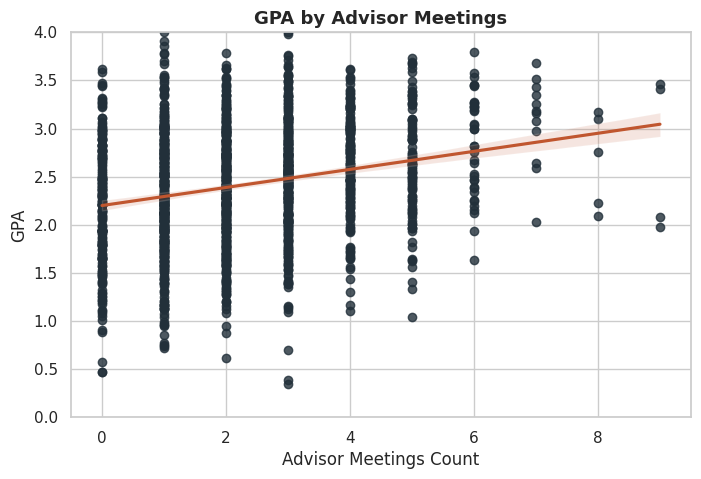

In [40]:
# Copy the closest cell from the Guided notebook, then fill in the blanks.
#
#   fig, ax = plt.subplots()
#   sns.__________(data=________, x="__________", color=NAVY, ax=ax)   # which chart? which column(s)?
#   ax.set_title("__________")
#   ax.set_xlabel("__________")
#   ax.set_ylabel("__________")
#   plt.show()

# --- your code below ---

fig, ax = plt.subplots()
filtered_students = students[(students['final_gpa'] != 0.0) & (students['dropped_out'] == 0)]
sns.regplot(data=filtered_students, x="advisor_meetings", y="final_gpa", scatter_kws={'color': NAVY}, line_kws={'color': RUST}, ax=ax)
ax.set_title("GPA by Advisor Meetings")
ax.set_xlabel("Advisor Meetings Count")
ax.set_ylabel("GPA")
ax.set_ylim(0, 4)
ax.set_xlim(-0.5, 9.5)
plt.show()


**STAR story — Part B**

- **Scope —** This chart shows students' GPAs for those students with established GPAs and who are active (not dropped out) against the number of recorded advisor meetings. The data is from *Students* and utilizes the fields *advisor_meetings* and *final_gpa*. It includes a regression line to indicate correlation.

- **Track —** This chart is intended to provide an opportunity to analyze a possible correlation between the number of advisor meetings students attend and their GPA.

- **Articulate —** The data shows a moderately strong correlation with the number of advisor meetings attended and the GPA of those students.

- **Respond —** I would want to analyze the possible other explanations for the correlation in GPA with more advisor meetings such as comparing GPAs vs credits attempted.

# Before you submit — checklist
- [ ] The notebook **runs top to bottom** with no errors (Runtime → Restart and run all).
- [ ] All **6 charts** are present, each with a title, labeled axes, and units/legend where needed.
- [ ] Each chart has a **complete STAR story**, including any exceptions you spotted.
- [ ] Part B question is written in and answered.
- [ ] Pushed to **GitHub**, and the **GitHub link** is submitted in Canvas.

**Rubric (70 pts):** chart choice 10 · correct build 20 · labeling 10 · STAR reading 18 · Part B question 4 · submission & professionalism 8.